# Advent of Code 2015 - Day 17

https://adventofcode.com/2015/day/17

## Imports

In [ ]:
import base64
import warnings

import marimo as mo
import plotly.express as px
import plotly.graph_objects as go

from collections import namedtuple
from aoc.utils import read_data

## Day 17 - No Such Thing as Too Much

### General functions

In [ ]:
from collections.abc import Iterable, Iterator
from typing import Any

def combinations(iterable: Iterable[Any], r: int) -> Iterator[tuple[Any, ...]]:
    """Yield all r-length combinations of the items in an iterable.

    This function is a copy of the code that can be accessed by the link
    below, and it contains this docstring and some comments to make the
    algorithm more clear.

    https://docs.python.org/3/library/itertools.html#itertools.combinations

    Combinations are produced in lexicographic order of the positions of
    their items in the input. Each item is used at most once per
    combination, and the items within a combination keep their original
    order, so ('A', 'B') is produced but ('B', 'A') is not. If r is greater
    than the number of items, a ValueError is raised.

    Args:
        iterable (Iterable[Any]): The items to choose from. It is converted
            to a tuple up front, so a one-time iterator such as a generator
            works.
        r (int): The number of items in each combination.

    Yields:
        tuple: One combination of r items from the iterable.

    Raises:
        ValueError: If r is greater than the number of items in the
            iterable.

    Examples:
        >>> list(combinations('ABCD', 2))
        [('A', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'C'), ('B', 'D'), ('C', 'D')]
        >>> list(combinations(range(4), 3))
        [(0, 1, 2), (0, 1, 3), (0, 2, 3), (1, 2, 3)]
    """
    # Fixed, indexable copy of the items to pick combinations from
    pool = tuple(iterable)
    n = len(pool)

    if r > n:
        raise ValueError(
            f"Subsequence length ({r}) cannot be greater than length of iterable ({n})."
        )

    # `indices` holds the positions of the items you're currently picking from the pool.
    # Each entry is an index into pool, not an item itself.
    indices = list(range(r))

    # First combination is by taking the first `r` elements of the `pool`.
    yield tuple(pool[i] for i in indices)

    while True:
        # `i` is the position in `indices` that gets bumped: the rightmost index
        # that can still move without running past the end of the pool.
        # Since `i` represent the index on the `indices` variable, and `indices`
        # represents which elements from the `pool` to take, `i` is sort of a
        # double index variable, which is why this While loop is pretty hard to
        # understand from the code alone.
        for i in reversed(range(r)):
            if indices[i] != i + n - r:
                break
        else:
            # No index can move any further, so every combination has been produced.
            return

        indices[i] += 1

        # `j` walks over every position after `i`. Each one is reset to the smallest
        # valid index that follows its left neighbour, which keeps the indices
        # strictly increasing and the output in lexicographic order.
        # This for-loop only gets executed when the `break` is executed in the
        # other for loop.
        for j in range(i + 1, r):
            indices[j] = indices[j - 1] + 1

        yield tuple(pool[i] for i in indices)

In [ ]:
def all_combinations(iterable):
    """Yield all non-empty combinations of the items in an iterable.

    Combinations are yielded by size, starting with every single item and
    ending with the full set. Within each size, they follow the same order
    as `combinations`. The iterable is measured with `len`, so it must be a
    sized collection such as a list, tuple, or string, not a generator.

    Args:
        iterable: The items to choose from.

    Yields:
        tuple: One combination of one or more items from the iterable.

    Examples:
        >>> list(all_combinations('ABC'))
        [('A',), ('B',), ('C',), ('A', 'B'), ('A', 'C'), ('B', 'C'), ('A', 'B', 'C')]
    """
    for i in range(1, len(iterable) + 1):
        yield from combinations(iterable, i)

In [ ]:
ContainerCombination = namedtuple(
    "ContainerCombination",
    ["size", "containers", "container_indices", "fits_target"],
)

def get_all_container_combinations(
    puzzle_input: list[str],
    eggnog_target_volume: int,
) -> list:
    """Check every container combination against the target volume.

    Args:
        puzzle_input: Capacities of the available containers, as strings.
        eggnog_target_volume: The total volume, in liters, to match.

    Returns:
        list[ContainerCombination]: One entry per combination, with its
            size, the containers it uses, and whether it adds up to the
            target.
    """
    containers = sorted([int(x) for x in puzzle_input], reverse=True)
    all_container_combinations = []

    for container_indices in all_combinations(range(len(containers))):
        combination = tuple(containers[i] for i in container_indices)
        fits_target = sum(combination) == eggnog_target_volume
        all_container_combinations.append(
            ContainerCombination(
                len(combination), combination, container_indices, fits_target
            )
        )

    return all_container_combinations

In [ ]:
from collections import Counter

def plot_combinations_per_container_count(
    all_container_combinations: list,
    log_y_axis: bool,
) -> go.Figure:  # pyright: ignore[reportInvalidTypeForm]
    """Plot how many combinations of each container count fit the target.

    Each container count is one stacked bar. The bottom segment is the
    number of combinations that add up to the target volume, and the top
    segment is the number that do not.

    Args:
        all_container_combinations: Output of
            get_all_container_combinations, one ContainerCombination per
            combination of containers.
        log_y_axis: Whether to use a logarithmic y-axis.

    Returns:
        go.Figure: Stacked bar chart with one bar per container count.
    """
    fitting_counts = Counter(
        container_combination.size
        for container_combination in all_container_combinations
        if container_combination.fits_target
    )
    not_fitting_counts = Counter(
        container_combination.size
        for container_combination in all_container_combinations
        if not container_combination.fits_target
    )
    container_counts = list(
        range(1, max(c.size for c in all_container_combinations) + 1)
    )

    figure = go.Figure()
    figure.add_trace(
        go.Bar(
            x=container_counts,
            y=[fitting_counts[count] for count in container_counts],
            name="Adds up to target",
            marker={"color": "#2a9d8f"},
        )
    )
    figure.add_trace(
        go.Bar(
            x=container_counts,
            y=[not_fitting_counts[count] for count in container_counts],
            name="Does not add up",
            marker={"color": "#e76f51"},
        )
    )

    figure.update_layout(
        title="Combinations per number of containers",
        xaxis_title="Number of containers",
        yaxis_title="Number of combinations"
        + (" (log scale)" if log_y_axis else ""),
        yaxis_type="log" if log_y_axis else "linear",
        xaxis={"dtick": 1},
        barmode="stack",
        template="plotly_white",
    )

    return figure

In [ ]:
def plot_fitting_combinations(
    all_container_combinations: list,
) -> go.Figure:  # pyright: ignore[reportInvalidTypeForm]
    """Plot every fitting container combination as a stacked bar.

    Each fitting combination is one bar. Every container has a fixed color,
    so containers with the same capacity still get separate colors, and all
    bars have the same total height: the target volume.

    Args:
        all_container_combinations: Output of
            get_all_container_combinations, one ContainerCombination per
            combination of containers.

    Returns:
        go.Figure: Stacked bar chart with one bar per fitting combination.
    """
    fitting_combinations = [
        container_combination
        for container_combination in all_container_combinations
        if container_combination.fits_target
    ]

    capacity_by_index = {
        index: capacity
        for container_combination in all_container_combinations
        for index, capacity in zip(
            container_combination.container_indices,
            container_combination.containers,
        )
    }

    # Containers are ranked by capacity, so containers of similar size get
    # neighbouring colors on the gradient, while equal sizes still differ.
    ranked_indices = sorted(
        capacity_by_index, key=lambda index: (capacity_by_index[index], index)
    )
    gradient_positions = [
        rank / max(len(ranked_indices) - 1, 1)
        for rank in range(len(ranked_indices))
    ]
    gradient_colors = px.colors.sample_colorscale("Turbo", gradient_positions)
    color_by_index = dict(zip(ranked_indices, gradient_colors))

    fitting_sizes = sorted(
        {
            container_combination.size
            for container_combination in fitting_combinations
        }
    )
    if len(fitting_sizes) == 1:
        title = (
            f"{len(fitting_combinations)} combinations of {fitting_sizes[0]} "
            "containers holding the target volume"
        )
    else:
        title = (
            f"All {len(fitting_combinations)} container combinations holding "
            "the target volume"
        )

    figure = go.Figure()

    for index in sorted(capacity_by_index):
        capacity = capacity_by_index[index]
        heights = [
            capacity if index in container_combination.container_indices else 0
            for container_combination in fitting_combinations
        ]

        figure.add_trace(
            go.Bar(
                x=list(range(len(fitting_combinations))),
                y=heights,
                name=f"Container {index + 1} ({capacity} L)",
                marker={
                    "color": color_by_index[index],
                    "line": {"width": 0},
                },
                hovertemplate=f"Container {index + 1} ({capacity} L)<br>"
                "Combination %{x}<extra></extra>",
            )
        )

    figure.update_layout(
        title=title,
        xaxis_title="Combination",
        yaxis_title="Liters",
        barmode="stack",
        bargap=0,
        template="plotly_white",
    )

    return figure

### Solution - Part 1

In [ ]:
def exercise_17_1_find_different_combinations_of_containers(
    all_container_combinations: list,
) -> int:
    """Count the container combinations that fit the target volume.

    Args:
        all_container_combinations: Output of get_all_container_combinations,
            one ContainerCombination per combination of containers.

    Returns:
        int: The number of combinations whose capacities add up to the target
            volume.
    """
    number_of_different_combinations = len(
        [
            container_combination
            for container_combination in all_container_combinations
            if container_combination.fits_target
        ]
    )

    return number_of_different_combinations

#### Example data

In [ ]:
example_containers = ["20", "15", "10", "5", "5"]
example_target_volume = 25

example_container_combinations = get_all_container_combinations(
    puzzle_input=example_containers, eggnog_target_volume=example_target_volume
)

example_solution = exercise_17_1_find_different_combinations_of_containers(
    all_container_combinations=example_container_combinations
)

assert example_solution == 4

In [ ]:
figure_17_1_example_counts = plot_combinations_per_container_count(
    all_container_combinations=example_container_combinations,
    log_y_axis=False,
)

mo.accordion({"Interactive plot": figure_17_1_example_counts})  # pyright: ignore[reportUnusedExpression]

<marimo-plotly data-figure='{"data":[{"marker":{"color":"#2a9d8f"},"name":"Adds up to target","x":[1,2,3,4,5],"y":[0,3,1,0,0],"type":"bar"},{"marker":{"color":"#e76f51"},"name":"Does not add up","x":[1,2,3,4,5],"y":[5,7,9,5,1],"type":"bar"}],"layout":{"template":{"data":{"barpolar":[{"marker":{"line":{"color":"white","width":0.5},"pattern":{"fillmode":"overlay","size":10,"solidity":0.2}},"type":"barpolar"}],"bar":[{"error_x":{"color":"#2a3f5f"},"error_y":{"color":"#2a3f5f"},"marker":{"line":{"color":"white","width":0.5},"pattern":{"fillmode":"overlay","size":10,"solidity":0.2}},"type":"bar"}],"carpet":[{"aaxis":{"endlinecolor":"#2a3f5f","gridcolor":"#C8D4E3","linecolor":"#C8D4E3","minorgridcolor":"#C8D4E3","startlinecolor":"#2a3f5f"},"baxis":{"endlinecolor":"#2a3f5f","gridcolor":"#C8D4E3","linecolor":"#C8D4E3","minorgridcolor":"#C8D4E3","startlinecolor":"#2a3f5f"},"type":"carpet"}],"choropleth":[{"colorbar":{"outlinewidth":0,"ticks":""},"type":"choropleth"}],"contourcarpet":[{"colorbar":{"outlinewidth":0,"ticks":""},"type":"contourcarpet"}],"contour":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e"],[0.4444444444444444,"#bd3786"],[0.5555555555555556,"#d8576b"],[0.6666666666666666,"#ed7953"],[0.7777777777777778,"#fb9f3a"],[0.8888888888888888,"#fdca26"],[1.0,"#f0f921"]],"type":"contour"}],"heatmap":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e"],[0.4444444444444444,"#bd3786"],[0.5555555555555556,"#d8576b"],[0.6666666666666666,"#ed7953"],[0.7777777777777778,"#fb9f3a"],[0.8888888888888888,"#fdca26"],[1.0,"#f0f921"]],"type":"heatmap"}],"histogram2dcontour":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e"],[0.4444444444444444,"#bd3786"],[0.5555555555555556,"#d8576b"],[0.6666666666666666,"#ed7953"],[0.7777777777777778,"#fb9f3a"],[0.8888888888888888,"#fdca26"],[1.0,"#f0f921"]],"type":"histogram2dcontour"}],"histogram2d":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e"],[0.4444444444444444,"#bd3786"],[0.5555555555555556,"#d8576b"],[0.6666666666666666,"#ed7953"],[0.7777777777777778,"#fb9f3a"],[0.8888888888888888,"#fdca26"],[1.0,"#f0f921"]],"type":"histogram2d"}],"histogram":[{"marker":{"pattern":{"fillmode":"overlay","size":10,"solidity":0.2}},"type":"histogram"}],"mesh3d":[{"colorbar":{"outlinewidth":0,"ticks":""},"type":"mesh3d"}],"parcoords":[{"line":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"parcoords"}],"pie":[{"automargin":true,"type":"pie"}],"scatter3d":[{"line":{"colorbar":{"outlinewidth":0,"ticks":""}},"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scatter3d"}],"scattercarpet":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scattercarpet"}],"scattergeo":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scattergeo"}],"scattergl":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scattergl"}],"scattermapbox":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scattermapbox"}],"scattermap":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scattermap"}],"scatterpolargl":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scatterpolargl"}],"scatterpolar":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scatterpolar"}],"scatter":[{"fillpattern":{"fillmode":"overlay","size":10,"solidity":0.2},"type":"scatter"}],"scatterternary":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scatterternary"}],"surface":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e

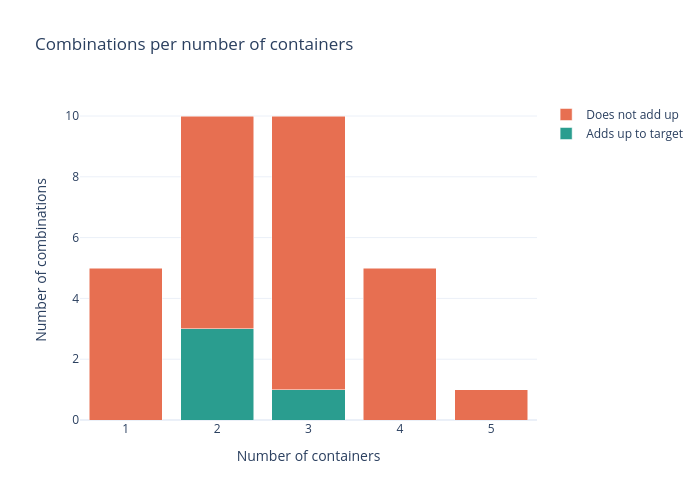

In [ ]:
# Kaleido 0.2.1 (pinned, as kaleido 1.x needs Chrome) raises a deprecation warning here.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    figure_png_17_1_example_counts = figure_17_1_example_counts.to_image(
        format="png"
    )

encoded_17_1_example_counts = base64.b64encode(
    figure_png_17_1_example_counts
).decode()

mo.md(
    f"![Combinations per container count (example data)](data:image/png;base64,{encoded_17_1_example_counts})"
)

In [ ]:
figure_17_1_example = plot_fitting_combinations(
    all_container_combinations=example_container_combinations,
)

mo.accordion({"Interactive plot": figure_17_1_example})  # pyright: ignore[reportUnusedExpression]

<marimo-plotly data-figure='{"data":[{"hovertemplate":"Container 1 (20 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(122, 4, 2)","line":{"width":0}},"name":"Container 1 (20 L)","x":[0,1,2,3],"y":[20,20,0,0],"type":"bar"},{"hovertemplate":"Container 2 (15 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(248, 127, 33)","line":{"width":0}},"name":"Container 2 (15 L)","x":[0,1,2,3],"y":[0,0,15,15],"type":"bar"},{"hovertemplate":"Container 3 (10 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(164, 252, 59)","line":{"width":0}},"name":"Container 3 (10 L)","x":[0,1,2,3],"y":[0,0,10,0],"type":"bar"},{"hovertemplate":"Container 4 (5 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(48, 18, 59)","line":{"width":0}},"name":"Container 4 (5 L)","x":[0,1,2,3],"y":[5,0,0,5],"type":"bar"},{"hovertemplate":"Container 5 (5 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(42, 184, 232)","line":{"width":0}},"name":"Container 5 (5 L)","x":[0,1,2,3],"y":[0,5,0,5],"type":"bar"}],"layout":{"template":{"data":{"barpolar":[{"marker":{"line":{"color":"white","width":0.5},"pattern":{"fillmode":"overlay","size":10,"solidity":0.2}},"type":"barpolar"}],"bar":[{"error_x":{"color":"#2a3f5f"},"error_y":{"color":"#2a3f5f"},"marker":{"line":{"color":"white","width":0.5},"pattern":{"fillmode":"overlay","size":10,"solidity":0.2}},"type":"bar"}],"carpet":[{"aaxis":{"endlinecolor":"#2a3f5f","gridcolor":"#C8D4E3","linecolor":"#C8D4E3","minorgridcolor":"#C8D4E3","startlinecolor":"#2a3f5f"},"baxis":{"endlinecolor":"#2a3f5f","gridcolor":"#C8D4E3","linecolor":"#C8D4E3","minorgridcolor":"#C8D4E3","startlinecolor":"#2a3f5f"},"type":"carpet"}],"choropleth":[{"colorbar":{"outlinewidth":0,"ticks":""},"type":"choropleth"}],"contourcarpet":[{"colorbar":{"outlinewidth":0,"ticks":""},"type":"contourcarpet"}],"contour":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e"],[0.4444444444444444,"#bd3786"],[0.5555555555555556,"#d8576b"],[0.6666666666666666,"#ed7953"],[0.7777777777777778,"#fb9f3a"],[0.8888888888888888,"#fdca26"],[1.0,"#f0f921"]],"type":"contour"}],"heatmap":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e"],[0.4444444444444444,"#bd3786"],[0.5555555555555556,"#d8576b"],[0.6666666666666666,"#ed7953"],[0.7777777777777778,"#fb9f3a"],[0.8888888888888888,"#fdca26"],[1.0,"#f0f921"]],"type":"heatmap"}],"histogram2dcontour":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e"],[0.4444444444444444,"#bd3786"],[0.5555555555555556,"#d8576b"],[0.6666666666666666,"#ed7953"],[0.7777777777777778,"#fb9f3a"],[0.8888888888888888,"#fdca26"],[1.0,"#f0f921"]],"type":"histogram2dcontour"}],"histogram2d":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e"],[0.4444444444444444,"#bd3786"],[0.5555555555555556,"#d8576b"],[0.6666666666666666,"#ed7953"],[0.7777777777777778,"#fb9f3a"],[0.8888888888888888,"#fdca26"],[1.0,"#f0f921"]],"type":"histogram2d"}],"histogram":[{"marker":{"pattern":{"fillmode":"overlay","size":10,"solidity":0.2}},"type":"histogram"}],"mesh3d":[{"colorbar":{"outlinewidth":0,"ticks":""},"type":"mesh3d"}],"parcoords":[{"line":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"parcoords"}],"pie":[{"automargin":true,"type":"pie"}],"scatter3d":[{"line":{"colorbar":{"outlinewidth":0,"ticks":""}},"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scatter3d"}],"scattercarpet":[{"marker":{"colorbar":{"outlinewidth":0,"tic

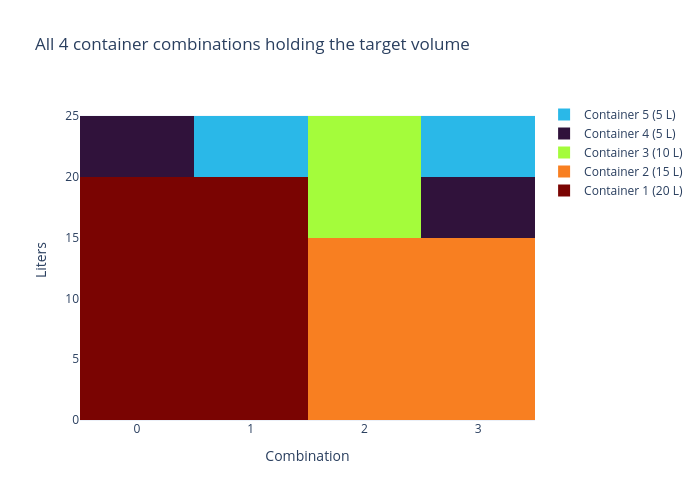

In [ ]:
# Kaleido 0.2.1 (pinned, as kaleido 1.x needs Chrome) raises a deprecation warning here.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    figure_png_17_1_example = figure_17_1_example.to_image(format="png")

encoded_17_1_example = base64.b64encode(figure_png_17_1_example).decode()

mo.md(
    f"![Fitting combinations (example data)](data:image/png;base64,{encoded_17_1_example})"
)

#### Real data

In [ ]:
containers = read_data(file_path="data/2015/2015_day_17.txt", separator="\n")
eggnog_target_volume = 150

container_combinations = get_all_container_combinations(
    puzzle_input=containers, eggnog_target_volume=eggnog_target_volume
)

solution_17_1 = exercise_17_1_find_different_combinations_of_containers(
    all_container_combinations=container_combinations
)

assert solution_17_1 == 654

In [ ]:
figure_17_1_counts = plot_combinations_per_container_count(
    all_container_combinations=container_combinations,
    log_y_axis=True,
)

mo.accordion({"Interactive plot": figure_17_1_counts})  # pyright: ignore[reportUnusedExpression]

<marimo-plotly data-figure='{"data":[{"marker":{"color":"#2a9d8f"},"name":"Adds up to target","x":[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],"y":[0,0,0,57,231,262,97,7,0,0,0,0,0,0,0,0,0,0,0,0],"type":"bar"},{"marker":{"color":"#e76f51"},"name":"Does not add up","x":[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],"y":[20,190,1140,4788,15273,38498,77423,125963,167960,184756,167960,125970,77520,38760,15504,4845,1140,190,20,1],"type":"bar"}],"layout":{"template":{"data":{"barpolar":[{"marker":{"line":{"color":"white","width":0.5},"pattern":{"fillmode":"overlay","size":10,"solidity":0.2}},"type":"barpolar"}],"bar":[{"error_x":{"color":"#2a3f5f"},"error_y":{"color":"#2a3f5f"},"marker":{"line":{"color":"white","width":0.5},"pattern":{"fillmode":"overlay","size":10,"solidity":0.2}},"type":"bar"}],"carpet":[{"aaxis":{"endlinecolor":"#2a3f5f","gridcolor":"#C8D4E3","linecolor":"#C8D4E3","minorgridcolor":"#C8D4E3","startlinecolor":"#2a3f5f"},"baxis":{"endlinecolor":"#2a3f5f","gridcolor":"#C8D4E3","linecolor":"#C8D4E3","minorgridcolor":"#C8D4E3","startlinecolor":"#2a3f5f"},"type":"carpet"}],"choropleth":[{"colorbar":{"outlinewidth":0,"ticks":""},"type":"choropleth"}],"contourcarpet":[{"colorbar":{"outlinewidth":0,"ticks":""},"type":"contourcarpet"}],"contour":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e"],[0.4444444444444444,"#bd3786"],[0.5555555555555556,"#d8576b"],[0.6666666666666666,"#ed7953"],[0.7777777777777778,"#fb9f3a"],[0.8888888888888888,"#fdca26"],[1.0,"#f0f921"]],"type":"contour"}],"heatmap":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e"],[0.4444444444444444,"#bd3786"],[0.5555555555555556,"#d8576b"],[0.6666666666666666,"#ed7953"],[0.7777777777777778,"#fb9f3a"],[0.8888888888888888,"#fdca26"],[1.0,"#f0f921"]],"type":"heatmap"}],"histogram2dcontour":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e"],[0.4444444444444444,"#bd3786"],[0.5555555555555556,"#d8576b"],[0.6666666666666666,"#ed7953"],[0.7777777777777778,"#fb9f3a"],[0.8888888888888888,"#fdca26"],[1.0,"#f0f921"]],"type":"histogram2dcontour"}],"histogram2d":[{"colorbar":{"outlinewidth":0,"ticks":""},"colorscale":[[0.0,"#0d0887"],[0.1111111111111111,"#46039f"],[0.2222222222222222,"#7201a8"],[0.3333333333333333,"#9c179e"],[0.4444444444444444,"#bd3786"],[0.5555555555555556,"#d8576b"],[0.6666666666666666,"#ed7953"],[0.7777777777777778,"#fb9f3a"],[0.8888888888888888,"#fdca26"],[1.0,"#f0f921"]],"type":"histogram2d"}],"histogram":[{"marker":{"pattern":{"fillmode":"overlay","size":10,"solidity":0.2}},"type":"histogram"}],"mesh3d":[{"colorbar":{"outlinewidth":0,"ticks":""},"type":"mesh3d"}],"parcoords":[{"line":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"parcoords"}],"pie":[{"automargin":true,"type":"pie"}],"scatter3d":[{"line":{"colorbar":{"outlinewidth":0,"ticks":""}},"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scatter3d"}],"scattercarpet":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scattercarpet"}],"scattergeo":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scattergeo"}],"scattergl":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scattergl"}],"scattermapbox":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scattermapbox"}],"scattermap":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scattermap"}],"scatterpolargl":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scatterpolargl"}],"scatterpolar":[{"marker":{"colorbar":{"outlinewidth":0,"ticks":""}},"type":"scatterpolar"}],"scatter":[{"fillpattern":{"fillmode":"overlay","size":10,"solidity":0.2},"type":"scatter"}],"scatterternary":[{"marker":{"colorbar":{"outlinewidth"

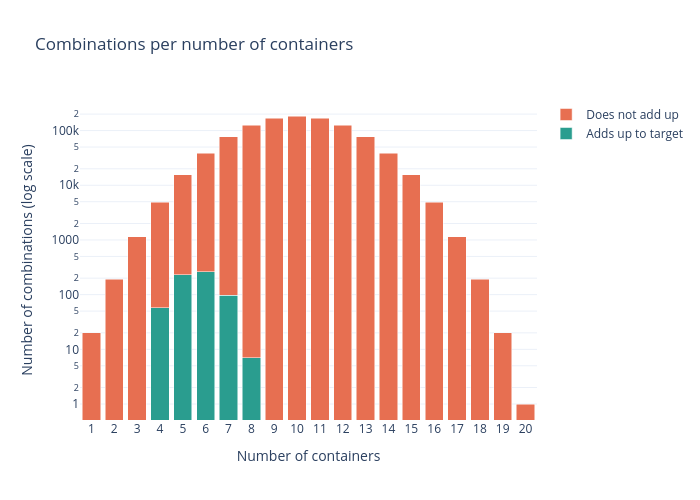

In [ ]:
# Kaleido 0.2.1 (pinned, as kaleido 1.x needs Chrome) raises a deprecation warning here.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    figure_png_17_1_counts = figure_17_1_counts.to_image(format="png")

encoded_17_1_counts = base64.b64encode(figure_png_17_1_counts).decode()

mo.md(
    f"![Combinations per container count (real data)](data:image/png;base64,{encoded_17_1_counts})"
)

In [ ]:
figure_17_1 = plot_fitting_combinations(
    all_container_combinations=container_combinations,
)

mo.accordion({"Interactive plot": figure_17_1})  # pyright: ignore[reportUnusedExpression]

<marimo-plotly data-figure='{"data":[{"hovertemplate":"Container 1 (50 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(122, 4, 2)","line":{"width":0}},"name":"Container 1 (50 L)","x":[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,277,278,279,280,281,282,283,284,285,286,287,288,289,290,291,292,293,294,295,296,297,298,299,300,301,302,303,304,305,306,307,308,309,310,311,312,313,314,315,316,317,318,319,320,321,322,323,324,325,326,327,328,329,330,331,332,333,334,335,336,337,338,339,340,341,342,343,344,345,346,347,348,349,350,351,352,353,354,355,356,357,358,359,360,361,362,363,364,365,366,367,368,369,370,371,372,373,374,375,376,377,378,379,380,381,382,383,384,385,386,387,388,389,390,391,392,393,394,395,396,397,398,399,400,401,402,403,404,405,406,407,408,409,410,411,412,413,414,415,416,417,418,419,420,421,422,423,424,425,426,427,428,429,430,431,432,433,434,435,436,437,438,439,440,441,442,443,444,445,446,447,448,449,450,451,452,453,454,455,456,457,458,459,460,461,462,463,464,465,466,467,468,469,470,471,472,473,474,475,476,477,478,479,480,481,482,483,484,485,486,487,488,489,490,491,492,493,494,495,496,497,498,499,500,501,502,503,504,505,506,507,508,509,510,511,512,513,514,515,516,517,518,519,520,521,522,523,524,525,526,527,528,529,530,531,532,533,534,535,536,537,538,539,540,541,542,543,544,545,546,547,548,549,550,551,552,553,554,555,556,557,558,559,560,561,562,563,564,565,566,567,568,569,570,571,572,573,574,575,576,577,578,579,580,581,582,583,584,585,586,587,588,589,590,591,592,593,594,595,596,597,598,599,600,601,602,603,604,605,606,607,608,609,610,611,612,613,614,615,616,617,618,619,620,621,622,623,624,625,626,627,628,629,630,631,632,633,634,635,636,637,638,639,640,641,642,643,644,645,646,647,648,649,650,651,652,653],"y":[50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,50,50,50,50,50,50,50,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0

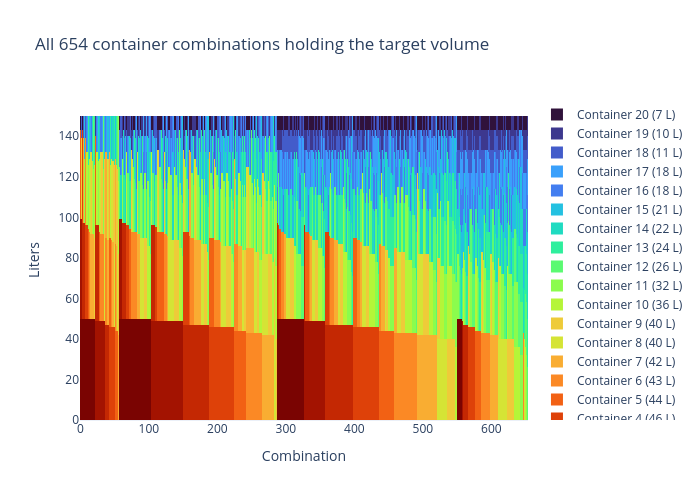

In [ ]:
# Kaleido 0.2.1 (pinned, as kaleido 1.x needs Chrome) raises a deprecation warning here.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    figure_png_17_1 = figure_17_1.to_image(format="png")

encoded_17_1 = base64.b64encode(figure_png_17_1).decode()

mo.md(f"![Fitting combinations (real data)](data:image/png;base64,{encoded_17_1})")

In [ ]:
fitting_sizes = sorted({c.size for c in container_combinations if c.fits_target})

figures_per_container_count = {
    size: plot_fitting_combinations(
        all_container_combinations=[
            container_combination
            for container_combination in container_combinations
            if container_combination.size == size
        ],
    )
    for size in fitting_sizes
}

mo.vstack(  # pyright: ignore[reportUnusedExpression]
    [
        mo.accordion({f"Interactive plot ({size} containers)": figure})
        for size, figure in figures_per_container_count.items()
    ]
)

<marimo-plotly data-figure='{"data":[{"hovertemplate":"Container 1 (50 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(122, 4, 2)","line":{"width":0}},"name":"Container 1 (50 L)","x":[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56],"y":[50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,50,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"type":"bar"},{"hovertemplate":"Container 2 (49 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(163, 19, 1)","line":{"width":0}},"name":"Container 2 (49 L)","x":[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56],"y":[49,49,49,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,49,49,49,49,49,49,49,49,49,49,49,49,49,49,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"type":"bar"},{"hovertemplate":"Container 3 (47 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(196, 40, 3)","line":{"width":0}},"name":"Container 3 (47 L)","x":[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56],"y":[0,0,0,47,47,47,47,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,47,47,47,47,47,0,0,0,0,0,0,0,0,0,47,47,47,47,47,47,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"type":"bar"},{"hovertemplate":"Container 4 (46 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(222, 65, 9)","line":{"width":0}},"name":"Container 4 (46 L)","x":[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56],"y":[0,0,0,46,0,0,0,46,46,46,46,46,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,46,0,0,0,0,0,0,0,0,46,0,0,0,0,0,46,46,46,46,46,46,46,46,46,0,0,0,0,0,0],"type":"bar"},{"hovertemplate":"Container 5 (44 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(242, 97, 20)","line":{"width":0}},"name":"Container 5 (44 L)","x":[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56],"y":[44,0,0,0,0,0,0,44,0,0,0,0,44,0,0,0,0,0,0,0,0,0,44,0,0,0,0,44,44,0,0,0,0,0,0,0,0,0,0,0,0,0,44,44,44,0,0,0,0,0,0,44,44,44,44,0,0],"type":"bar"},{"hovertemplate":"Container 6 (43 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(251, 137, 37)","line":{"width":0}},"name":"Container 6 (43 L)","x":[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56],"y":[0,0,0,0,43,0,0,0,43,0,0,0,0,43,0,0,0,0,0,0,0,0,0,43,0,0,0,0,0,43,43,43,43,43,43,0,0,43,43,43,0,0,0,0,0,43,43,0,0,0,0,43,0,0,0,0,0],"type":"bar"},{"hovertemplate":"Container 7 (42 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(249, 173, 50)","line":{"width":0}},"name":"Container 7 (42 L)","x":[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56],"y":[0,0,0,0,0,42,0,0,0,0,0,0,0,0,42,42,42,42,42,42,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,42,42,0,42,42,42,42,0,0,0,42,42,42,0,42,42,42,0,42,42],"type":"bar"},{"hovertemplate":"Container 8 (40 L)\u003cbr\u003eCombination %{x}\u003cextra\u003e\u003c/extra\u003e","marker":{"color":"rgb(213, 228, 53)","line":{"width":0}},"name":"Container 8 (40 L)","x":[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56],"y":[0,40,0,0,0,0,0,0,0,0,0,0,0,0,40,40,0,0,0,0,40,0,0,0,0,0,0,0,0

#### 4 containers

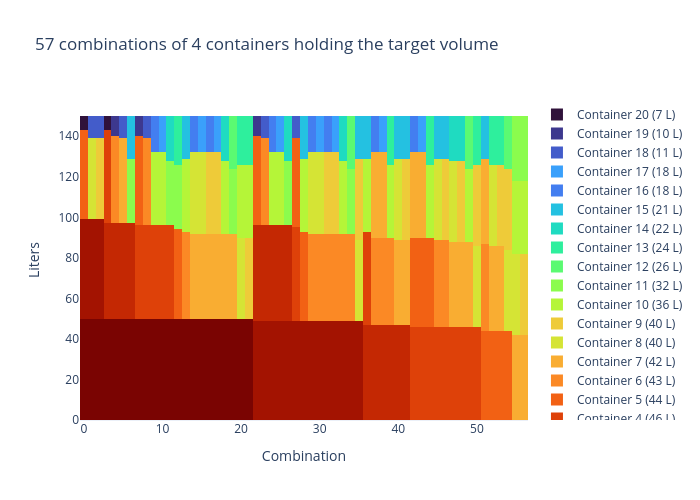

#### 5 containers

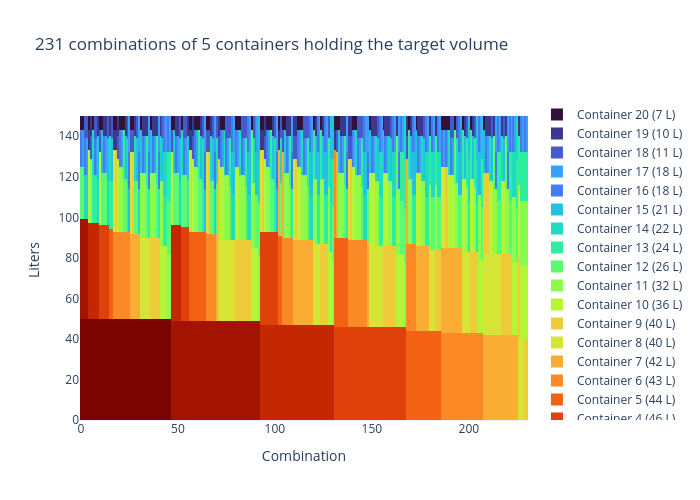

#### 6 containers

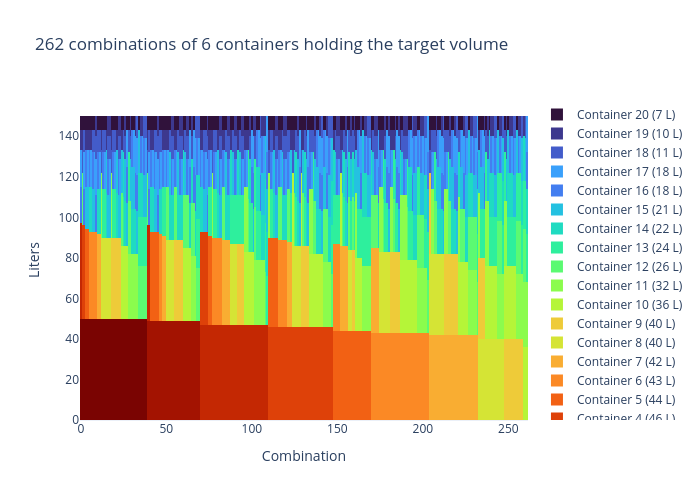

#### 7 containers

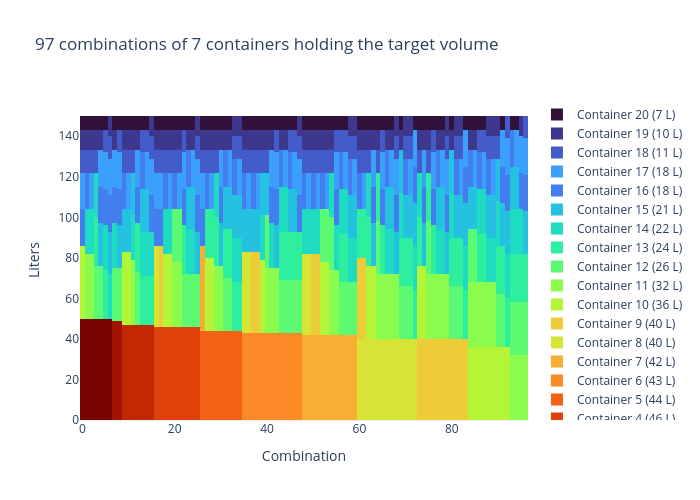

#### 8 containers

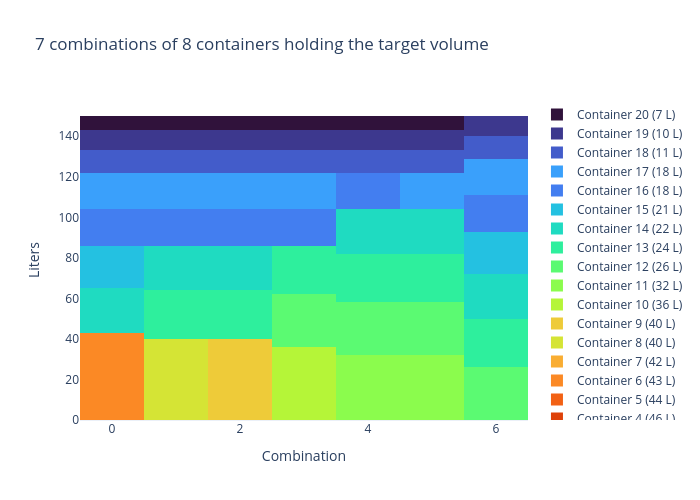

In [ ]:
# Kaleido 0.2.1 (pinned, as kaleido 1.x needs Chrome) raises a deprecation warning here.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    encoded_figures_per_container_count = {
        size: base64.b64encode(figure.to_image(format="png")).decode()
        for size, figure in figures_per_container_count.items()
    }

mo.md(  # pyright: ignore[reportUnusedExpression]
    "\n\n".join(
        f"#### {size} containers\n\n![Fitting combinations ({size} containers)](data:image/png;base64,{encoded})"
        for size, encoded in encoded_figures_per_container_count.items()
    )
)

### Part 2 - Solution

In [ ]:
def exercise_17_2_find_combinations_for_minimum(
    all_container_combinations: list,
) -> int:
    """Count the fitting combinations that use the fewest containers.

    Args:
        all_container_combinations: Output of get_all_container_combinations,
            one ContainerCombination per combination of containers.

    Returns:
        int: The number of combinations with the smallest size that add up to
            the target volume. If no combination fits, the function returns 0.
    """
    fitting_combinations = [
        container_combination
        for container_combination in all_container_combinations
        if container_combination.fits_target
    ]

    if not fitting_combinations:
        return 0

    smallest_size = min(
        container_combination.size for container_combination in fitting_combinations
    )

    number_of_different_combinations = len(
        [
            container_combination
            for container_combination in fitting_combinations
            if container_combination.size == smallest_size
        ]
    )

    return number_of_different_combinations

In [ ]:
solution_17_2 = exercise_17_2_find_combinations_for_minimum(
    all_container_combinations=container_combinations,
)

assert solution_17_2 == 57